# 15 - anomalib : PaDiM, STFPM, FastFlow... derriere le meme protocole

anomalib (Apache-2.0) fournit des dizaines de methodes d'anomalies. On s'en sert comme d'une
bibliotheque de MODELES, en gardant pour nous tout ce qui doit rester identique d'une methode a
l'autre pour qu'elles soient comparables :
- le decoupage (anomalib ne voit QUE les normales d'entrainement : ni validation, ni test) ;
- la carte brute -> carte lissee -> score (meme module pour toutes les methodes) ;
- le seuil, calibre sur nos normales de validation (quantile 0,99) ;
- les metriques, l'export ONNX et la carte du modele (servie par la production).

Methodes du mode QUICK (CPU) :
- **PaDiM** : une gaussienne par position (moyenne + covariance des caracteristiques normales),
  distance de Mahalanobis ; pas d'entrainement, tres rapide, ideal pour des pieces alignees ;
- **STFPM** : un reseau etudiant apprend a imiter un professeur pre-entraine sur les normales ;
  la ou ils divergent, l'image est anormale ;
- **FastFlow** : un flot normalisant modelise la densite des caracteristiques normales.
En mode complet (`QUICK = False`, GPU conseille) : PatchCore d'anomalib, Reverse Distillation,
EfficientAd et DRAEM (ces deux derniers telechargent un jeu auxiliaire : Imagenette, DTD).

Prerequis : extra `anomaly` (anomalib) ; `python tools/get_data/get_mvtec_bottle.py`. Le backbone
resnet18 est celui de timm : sans Internet, il doit etre dans le cache Hugging Face et la
variable `HF_HUB_OFFLINE=1` doit etre posee AVANT d'importer anomalib (fait ci-dessous).

Duree en mode QUICK sur un CPU 2 coeurs : environ 8 minutes.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter
  -> 7 Charger par lots, 8 Modele, 9 Perte et optimiseur, 10 Entrainer (anomalib fait les
     quatre : une fonction `fit` par methode)
  -> 11 Evaluer (meme seuil, memes metriques pour toutes les methodes, puis comparaison)
  -> 12 Sauvegarder et exporter -> 13 Predire (dans "Passer en production")
```

Pas d'augmentation ici (etape 6). L'etape 2 (importer et explorer) est dans les notebooks 00,
01 et 05.

## Etape 1 - Imports et reglages

Une seule cellule : les imports, puis le bloc REGLAGES (tout ce qu'on change pour ses propres
donnees est la, et seulement la), le dossier de sortie et la graine du hasard.

In [1]:
import os  # os : acces au systeme (ici, les variables d'environnement)

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # backbone timm depuis le cache local (poste sans Internet), seulement si non deja regle

import json  # json : ecrit la carte du modele dans un fichier texte lisible
import logging  # logging : regle le niveau des messages affiches par les bibliotheques
import shutil  # shutil : supprime des dossiers entiers
import time  # time : chronometre les etapes et date la carte du modele
import warnings  # warnings : masque les avertissements sans importance
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele au format ONNX (format d'echange, sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (une ligne par image) faciles a filtrer et a grouper
import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres a plusieurs dimensions) et reseaux de neurones
import torch.nn as nn  # nn : briques des reseaux de neurones (couches, modules)
import torch.nn.functional as F  # F : fonctions de calcul sans poids (interpolation, convolution...)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.metrics import f1_score, roc_auc_score  # metriques : F1 (rappel et precision combines) et AUROC (qualite du classement)
from sklearn.model_selection import train_test_split  # tire au hasard une partie des lignes (pour la validation)

from vtb import viz  # viz : affichage de la boite a outils (grilles d'images, courbes, tableaux)

# ---- REGLAGES : tout ce qu'on change pour ses propres donnees ------------------------------
QUICK = True  # True : PaDiM, STFPM, FastFlow (FastFlow a 5 epoques au lieu de 15) ; False : toutes les methodes
DATA_DIR = Path("data/raw/mvtec_bottle")  # rangement MVTec : train/good, test/<type>, ground_truth/<type>/<nom>_mask.png
COLOR = "rgb"  # images lues en couleur (3 canaux)
IMAGE_SIZE = 256  # cote des images apres resize ; les cartes d'anomalie ont cette taille
VAL_FRACTION = 0.15  # 15 % des normales d'entrainement mises de cote pour calibrer le seuil
SIGMA = 4.0  # lissage gaussien de la carte, en pixels
IMAGE_QUANTILE, PIXEL_QUANTILE = 0.99, 0.999  # seuils = quantiles des normales de validation (0,99 : 1 % des normales au-dessus)
SEED = 42  # graine du hasard : memes tirages a chaque execution, resultats reproductibles
BACKBONE = "resnet18"  # reseau pre-entraine qui decrit les images ; les articles utilisent souvent wide_resnet50_2 (plus lent, GPU)
METHODS = {  # nom de classe anomalib -> (arguments du modele, epoques, taille de lot)
    "Padim": ({"backbone": BACKBONE, "layers": ["layer1", "layer2", "layer3"]}, None, 16),  # PaDiM : pas d'entrainement (None)
    "Stfpm": ({"backbone": BACKBONE, "layers": ["layer1", "layer2", "layer3"]}, 15, 16),  # STFPM : 15 epoques (5 ne suffisent pas)
    "Fastflow": ({"backbone": BACKBONE, "flow_steps": 8}, 5 if QUICK else 15, 16),  # FastFlow : 8 etapes de flot, 5 ou 15 epoques
}
if not QUICK:  # en mode complet, on ajoute les methodes lourdes
    METHODS.update(  # ajoute au dictionnaire ...
        {  # ... ces 4 methodes
            # PatchCore d'anomalib : memoire de 1 % des vecteurs, sans entrainement
            "Patchcore": ({"backbone": BACKBONE, "layers": ["layer2", "layer3"], "coreset_sampling_ratio": 0.01}, None, 16),
            "ReverseDistillation": ({"backbone": BACKBONE, "layers": ["layer1", "layer2", "layer3"]}, 30, 16),  # 30 epoques
            "EfficientAd": ({"model_size": "small", "imagenet_dir": "data/raw/imagenette"}, 20, 1),  # telecharge Imagenette ; lots de 1
            "Draem": ({"dtd_dir": "data/raw/dtd"}, 30, 16),  # telecharge DTD (textures pour fabriquer des defauts)
        }
    )
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # calcul sur la carte graphique (GPU) si presente, sinon CPU
OUT = Path("outputs/notebooks/15_anomalies_anomalib")  # dossier ou ce notebook ecrit ses resultats
# --------------------------------------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
warnings.filterwarnings("ignore")  # masque tous les avertissements (anomalib et Lightning en emettent beaucoup)
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en resolution moderee et en jpeg : notebook plus leger


def quiet() -> None:  # baisse le niveau des messages des bibliotheques bavardes (rien a renvoyer)
    """Lightning et anomalib sont bavards : niveau WARNING (a rappeler apres leur import)."""
    for name in (  # pour chaque journal de messages (logger) de cette liste :
        "lightning",  # Lightning : la bibliotheque qui fait tourner l'entrainement pour anomalib
        "lightning.pytorch",  # sa partie PyTorch
        "lightning.pytorch.utilities.rank_zero",  # ses messages du processus principal
        "lightning.fabric",  # sa partie Fabric
        "lightning.fabric.utilities.rank_zero",  # idem pour Fabric
        "anomalib",  # anomalib elle-meme
        "torch.onnx",  # l'exporteur ONNX de PyTorch
        "onnxscript",  # l'outil utilise par le nouvel exporteur ONNX
    ):
        logging.getLogger(name).setLevel(logging.WARNING)  # n'affiche plus que les avertissements et les erreurs


import anomalib.models  # noqa: E402 - apres HF_HUB_OFFLINE ; anomalib.models : les classes de methodes (Padim, Stfpm...)
from anomalib.data.datasets import FolderDataset  # noqa: E402 - jeu de donnees anomalib qui lit un dossier d'images normales
from anomalib.engine import Engine  # noqa: E402 - Engine : lance l'entrainement (avec Lightning) d'un modele anomalib
from lightning.pytorch import seed_everything  # noqa: E402 - fixe d'un coup les graines de python, numpy et torch

quiet()  # a rappeler apres l'import : anomalib vient de regler ses propres niveaux de messages
# materiel, versions et methodes au programme
print("device :", DEVICE, "| torch", torch.__version__, "| anomalib", anomalib.__version__, "| methodes :", list(METHODS))

device : cpu | torch 2.15.0+cu132 | anomalib 2.7.0 | methodes : ['Padim', 'Stfpm', 'Fastflow']


## Etapes 3 et 4 - Cataloguer et decouper : le meme decoupage que les autres notebooks d'anomalies

Normales du train -> train / val ; le test (normales + defauts) est lu une fois. Meme graine
que la recette : les chiffres sont comparables a ceux de PatchCore (notebook 14) et de
l'auto-encodeur (notebook 13).

In [2]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")  # extensions reconnues comme images


def list_images(folder: Path) -> list[Path]:  # renvoie la liste triee des images d'un dossier et de ses sous-dossiers
    # tous les fichiers (rglob = recherche dans les sous-dossiers aussi) dont l'extension est une extension d'image
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


def mvtec_catalog(root: Path) -> pd.DataFrame:  # catalogue d'un dossier MVTec : une ligne par image ; renvoie un tableau pandas
    rows = [  # d'abord les images d'entrainement : toutes bonnes ("good")
        {"path": str(p), "label": "good", "defect_type": "good", "split": "train", "mask_path": ""}  # pas de masque : piece bonne
        for p in list_images(root / "train" / "good")  # pour chaque image de train/good
    ]
    for type_dir in sorted(d for d in (root / "test").iterdir() if d.is_dir()):  # pour chaque sous-dossier de test (good, broken...)
        for p in list_images(type_dir):  # pour chaque image de ce type
            mask = root / "ground_truth" / type_dir.name / f"{p.stem}_mask.png"  # chemin de son masque de verite (s'il existe)
            label = "good" if type_dir.name == "good" else "defect"  # etiquette image : bonne ou defaut
            rows.append(  # ajoute la ligne de cette image
                {  # une ligne du tableau
                    "path": str(p),  # chemin de l'image
                    "label": label,  # good ou defect
                    "defect_type": type_dir.name,  # type precis (nom du sous-dossier)
                    "split": "test",  # tout le dossier test va au test
                    "mask_path": str(mask) if mask.exists() else "",  # chemin du masque, vide s'il n'y en a pas
                }
            )
    return pd.DataFrame(rows)  # renvoie le catalogue


split = mvtec_catalog(DATA_DIR)  # catalogue MVTec bottle (train = normales, test = normales + defauts)
pool = split[(split["label"] == "good") & (split["split"] == "train")]  # normales d'entrainement (& = ET logique)
_, val_rows = train_test_split(pool, test_size=VAL_FRACTION, random_state=SEED)  # 15 % d'entre elles tirees au hasard (graine fixe)
split.loc[val_rows.index, "split"] = "val"  # ... et marquees "val"
assert split.loc[split["split"] != "test", "label"].eq("good").all()  # controle : train et val ne contiennent que des normales
split.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage
display(pd.crosstab(split["defect_type"], split["split"], margins=True))  # nombre d'images par type et par partie, avec totaux

split,test,train,val,All
defect_type,,,,
broken_large,20,0,0,20
broken_small,22,0,0,22
contamination,21,0,0,21
good,20,177,32,229
All,83,177,32,292


## Etape 5 - Pretraiter : images en memoire, et les normales d'entrainement ecrites pour anomalib

anomalib lit un DOSSIER d'images normales (`FolderDataset`). On y ecrit les normales
d'entrainement DEJA pretraitees (meme lecture, meme resize que la production), en PNG (sans
perte) : le modele voit exactement ce que la production lui enverra.

In [3]:
def read_image(path: str | Path, color: str = "rgb") -> np.ndarray:  # lit une image ; renvoie RGB (H, W, 3) ou gris (H, W)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)  # octets du fichier -> image (chemins accentues ok)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # arret avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si l'image a 4 canaux (couleur + transparence)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur
    if color == "gray":  # si on veut du gris
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja gris : inchange
    # sinon RGB : une image grise est copiee sur 3 canaux ; une image couleur passe de BGR (ordre OpenCV) a RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne une image en carre size x size
    shrinking = size * size < image.shape[0] * image.shape[1]  # vrai si l'image est reduite (moins de pixels a l'arrivee)
    # INTER_AREA (moyenne des pixels) pour reduire, interpolation lineaire pour agrandir
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)


def read_mask(path: str, size: int) -> np.ndarray:  # lit un masque de verite en 0/1 a la taille voulue
    if not path:  # chemin vide : image sans masque (piece normale)
        return np.zeros((size, size), np.uint8)  # masque tout a 0 : aucun pixel de defaut
    # blanc -> 1, noir -> 0 ; plus proche voisin pour que chaque pixel reste 0 ou 1
    return cv2.resize((read_image(path, "gray") > 127).astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST)


def to_tensor(images: np.ndarray) -> torch.Tensor:  # tableau d'images numpy -> tenseur (N, C, H, W) dans [0, 1]
    # nombres a virgule divises par la valeur maximale possible : 65535 en 16 bits, 255 en 8 bits
    x = torch.from_numpy(images.astype(np.float32) / (65535.0 if images.dtype == np.uint16 else 255.0))
    return x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()  # ajoute l'axe canal (gris) ou le met devant (couleur)


frames = {s: split[split["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}  # un tableau par partie
# images lues et redimensionnees de chaque partie, empilees en un tableau numpy par partie
images = {s: np.stack([resize(read_image(p, COLOR), IMAGE_SIZE) for p in frames[s]["path"]]) for s in frames}
x_val, x_test = to_tensor(images["val"]), to_tensor(images["test"])  # tenseurs de validation et de test (le train passe par des fichiers)
test_masks = np.stack([read_mask(m, IMAGE_SIZE) for m in frames["test"]["mask_path"]])  # masques de verite du test
test_labels = (frames["test"]["label"] == "defect").to_numpy().astype(int)  # verite par image du test : 1 = defaut, 0 = normale
test_types = frames["test"]["defect_type"].to_numpy()  # type de defaut de chaque image du test

train_dir = OUT / "anomalib_data" / "train" / "good"  # dossier ou anomalib lira les normales d'entrainement
shutil.rmtree(train_dir, ignore_errors=True)  # efface la copie d'un lancement precedent (pas d'erreur si elle n'existe pas)
train_dir.mkdir(parents=True)  # recree le dossier, vide
for i, (path, image) in enumerate(zip(frames["train"]["path"], images["train"])):  # pour chaque normale d'entrainement (numero i)
    bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) if image.ndim == 3 else image  # OpenCV ecrit en BGR : on repasse de RGB a BGR
    ok, buffer = cv2.imencode(".png", bgr)  # encode en PNG (sans perte) en memoire ; ok dit si l'encodage a reussi
    buffer.tofile(str(train_dir / f"{i:05d}_{Path(path).stem}.png"))  # ecrit le fichier : numero sur 5 chiffres + nom d'origine
print(f"{len(list(train_dir.iterdir()))} normales ecrites dans {train_dir}")  # nombre de fichiers ecrits

177 normales ecrites dans outputs/notebooks/15_anomalies_anomalib/anomalib_data/train/good


## Etapes 7 a 10 - De charger par lots a entrainer : construire, entrainer, puis lire la carte BRUTE

La fonction `fit` couvre quatre etapes du fil : DataLoader des normales (7), modele anomalib (8),
perte et optimiseur propres a chaque methode, caches dans la librairie (9), entrainement par
`Engine.fit` (10). La cellule definit aussi les fonctions de score et de metriques de l'etape 11.

- `cls.configure_pre_processor(image_size=...)` : le pre-traitement interne d'anomalib
  (redimensionnement + normalisation ImageNet) a la taille de nos images ; il fait partie du
  modele, donc de l'ONNX.
- `Engine.fit` avec un DataLoader d'entrainement SEUL : sans donnees de validation, Lightning
  saute la validation et anomalib ne fixe aucun seuil (on le fait nous-memes).
- Prediction : on appelle le reseau torch d'anomalib (`model.model`) et on lit sa carte
  d'anomalie brute, sans son post-traitement (qui normalise les scores avec SES seuils).
- Puis le module commun : resize, lissage gaussien, score = maximum.

In [4]:
def gaussian_kernel(sigma: float) -> torch.Tensor:  # noyau de flou gaussien 2D ; renvoie un tenseur (1, 1, k, k)
    radius = max(1, int(np.ceil(3 * sigma)))  # rayon = 3 sigma (au-dela la gaussienne est quasi nulle), au moins 1
    coords = torch.arange(-radius, radius + 1, dtype=torch.float32)  # positions -rayon ... +rayon
    kernel = torch.exp(-(coords**2) / (2 * sigma**2))  # courbe en cloche (gaussienne) a une dimension
    kernel = kernel / kernel.sum()  # somme ramenee a 1 : le flou ne change pas le niveau moyen
    return torch.outer(kernel, kernel)[None, None]  # produit exterieur -> noyau 2D ; [None, None] ajoute 2 axes (forme d'un filtre)


class MapToScore(nn.Module):  # module commun : carte brute -> carte lissee a la taille de l'image + score image
    def __init__(self, size: int, sigma: float) -> None:  # taille de sortie et force du lissage
        super().__init__()  # initialise la partie nn.Module (obligatoire)
        self.size = (size, size)  # taille finale de la carte (hauteur, largeur)
        # buffer : noyau range dans le modele (sauve et exporte avec lui) ; sigma = 0 : noyau neutre 1 x 1 (pas de flou)
        self.register_buffer("kernel", gaussian_kernel(sigma) if sigma > 0 else torch.ones(1, 1, 1, 1))

    def forward(self, raw: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (cartes lissees, scores)
        # remet la carte a la taille de l'image (interpolation bilineaire) si elle ne l'est pas deja
        maps = F.interpolate(raw, size=self.size, mode="bilinear", align_corners=False) if raw.shape[-2:] != self.size else raw
        radius = self.kernel.shape[-1] // 2  # rayon du noyau (0 pour le noyau neutre)
        if radius:  # si un lissage est demande
            maps = F.conv2d(F.pad(maps, (radius,) * 4, mode="reflect"), self.kernel)  # bords prolonges en miroir, puis flou (convolution)
        return maps, maps.flatten(1).amax(dim=1)  # carte lissee, et score image = valeur maximale de la carte


class AnomalibRawMap(nn.Module):  # module : image -> carte brute d'un modele anomalib (sans son post-traitement)
    """Pre-traitement + reseau torch d'anomalib : image [0, 1] -> carte brute (N, 1, h, w)."""

    def __init__(self, anomalib_model) -> None:  # recupere les deux morceaux utiles du modele anomalib
        super().__init__()  # initialise la partie nn.Module
        self.pre = anomalib_model.pre_processor  # pre-traitement d'anomalib : resize + normalisation ImageNet
        self.net = anomalib_model.model  # le reseau torch nu, sans le post-traitement d'anomalib

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # renvoie la carte brute (N, 1, h, w)
        if x.shape[1] == 1:  # si l'image n'a qu'un canal (gris)
            x = x.repeat(1, 3, 1, 1)  # copie sur 3 canaux : les reseaux pre-entraines attendent 3 canaux
        out = self.net(self.pre(x))  # pre-traitement puis reseau
        # la carte : attribut anomaly_map du resultat s'il existe, sinon 2e element du resultat
        anomaly_map = out.anomaly_map if hasattr(out, "anomaly_map") else out[1]
        return anomaly_map if anomaly_map.ndim == 4 else anomaly_map[:, None]  # ajoute l'axe canal s'il manque : (N, 1, h, w)


class AnomalyModel(nn.Module):  # modele complet : image -> (carte, score), meme schema pour toutes les methodes
    def __init__(self, raw_map: nn.Module, to_score: MapToScore) -> None:  # assemble les deux etages
        super().__init__()  # initialise la partie nn.Module
        self.raw_map, self.to_score = raw_map, to_score  # etage 1 : carte brute ; etage 2 : lissage et score

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (carte lissee, score)
        return self.to_score(self.raw_map(x))  # carte brute, puis lissage et score


def fit(name: str, params: dict, epochs: int | None, batch_size: int):  # construit et entraine une methode ; renvoie le modele anomalib
    """Instancie le modele anomalib par son nom, puis l'entraine (ou construit sa memoire) sur les normales seules."""
    logging.disable(logging.INFO)  # Lightning ecrit ses messages INFO malgre les niveaux : coupes le temps de l'entrainement
    try:  # quoi qu'il arrive pendant l'entrainement ...
        return _fit(name, params, epochs, batch_size)  # ... (le vrai travail est dans _fit) ...
    finally:  # ... ce bloc s'execute toujours, meme en cas d'erreur :
        logging.disable(logging.NOTSET)  # on retablit les messages normaux


def _fit(name: str, params: dict, epochs: int | None, batch_size: int):  # construit le modele et l'entraine sur le dossier des normales
    seed_everything(SEED, verbose=False)  # AVANT de construire : PaDiM tire ses canaux au hasard, PatchCore son premier vecteur
    cls = getattr(anomalib.models, name)  # la classe anomalib qui porte ce nom (ex. anomalib.models.Padim)
    # instancie le modele : pre-traitement a la taille de nos images, plus ses arguments (** deplie le dictionnaire)
    model = cls(pre_processor=cls.configure_pre_processor(image_size=(IMAGE_SIZE, IMAGE_SIZE)), **params)
    engine = Engine(  # le moteur d'entrainement d'anomalib (Lightning dessous)
        default_root_dir=OUT / "lightning" / name,  # dossier de travail de Lightning (points de sauvegarde)
        accelerator="gpu" if DEVICE.type == "cuda" else "cpu",  # GPU si disponible, sinon CPU
        devices=1,  # un seul appareil
        logger=False,  # pas de journal d'experience
        enable_progress_bar=False,  # pas de barre de progression
        enable_model_summary=False,  # pas de resume du modele
        # nombre d'epoques s'il est fixe (rien pour les methodes sans entrainement)
        **({"max_epochs": epochs} if epochs is not None else {}),
    )
    quiet()  # Lightning vient de remettre ses niveaux de messages : on les rebaisse
    if name == "EfficientAd":  # lit trainer.datamodule pendant l'entrainement : validation tiree des NORMALES du train
        from anomalib.data import Folder  # Folder : module de donnees anomalib complet (train + validation) sur un dossier

        datamodule = Folder(  # donnees lues depuis notre dossier de normales
            name="nb15",  # nom du jeu de donnees
            root=train_dir.parent.parent,  # racine : OUT/anomalib_data
            normal_dir="train/good",  # sous-dossier des normales
            train_batch_size=batch_size,  # taille de lot d'entrainement
            eval_batch_size=batch_size,  # taille de lot d'evaluation
            num_workers=0,  # lecture dans le processus principal (plus simple, marche partout)
            test_split_mode="none",  # pas de test ici : le notre est a part
            val_split_mode="from_train",  # validation prise dans les normales d'entrainement
            val_split_ratio=0.1,  # 10 % d'entre elles
            seed=SEED,  # graine du tirage
        )
        engine.fit(model, datamodule=datamodule)  # entrainement
    else:  # toutes les autres methodes
        dataset = FolderDataset(name="nb15", normal_dir=train_dir, split="train")  # jeu de donnees : les normales du dossier
        loader = torch.utils.data.DataLoader(  # DataLoader : sert les images par lots
            dataset,  # les donnees
            batch_size=batch_size,  # images par lot
            shuffle=True,  # ordre melange a chaque epoque
            num_workers=0,  # lecture dans le processus principal
            collate_fn=dataset.collate_fn,  # fonction d'anomalib qui assemble les images d'un lot
            generator=torch.Generator().manual_seed(SEED),  # melange reproductible (graine fixe)
        )
        engine.fit(model, train_dataloaders=loader)  # entrainement (ou construction de la memoire) avec ce seul DataLoader
    shutil.rmtree(OUT / "lightning" / name, ignore_errors=True)  # checkpoints Lightning : inutiles ici
    return model  # le modele anomalib pret


@torch.no_grad()  # pas de calcul de gradient : plus rapide, moins de memoire
def score_images(model: nn.Module, x: torch.Tensor, batch_size: int = 16) -> tuple[np.ndarray, np.ndarray]:  # renvoie (scores, cartes)
    model.eval().to(DEVICE)  # mode evaluation, sur GPU ou CPU
    scores, maps = [], []  # resultats lot par lot
    for i in range(0, len(x), batch_size):  # pour chaque lot de batch_size images
        m, s = model(x[i : i + batch_size].to(DEVICE))  # cartes et scores du lot
        maps.append(m[:, 0].cpu())  # cartes sans l'axe canal, ramenees sur CPU
        scores.append(s.cpu())  # scores ramenes sur CPU
    return torch.cat(scores).numpy(), torch.cat(maps).numpy()  # tout recolle, en tableaux numpy


def anomaly_metrics(scores, maps, masks, labels, threshold, types) -> dict:  # metriques image et pixel ; renvoie un dictionnaire
    decisions = (scores > threshold).astype(int)  # decision par image : 1 = anomalie (score au-dessus du seuil)
    flat_masks, flat_maps = masks.reshape(-1), maps.reshape(-1)  # tous les pixels mis a plat
    step = max(1, flat_masks.size // 4_000_000)  # sous-echantillonnage : au plus ~4 millions de pixels, pour aller vite
    return {  # dictionnaire des metriques
        # AUROC : chance qu'un defaut tire au hasard ait un score plus haut qu'une normale (1 = parfait, 0,5 = hasard)
        "auroc_image": float(roc_auc_score(labels, scores)),
        "auroc_pixel": float(roc_auc_score(flat_masks[::step], flat_maps[::step])),  # meme idee au pixel : 1 pixel sur `step`
        "recall": float(decisions[labels == 1].mean()),  # rappel : part des defauts detectes
        "false_alarm_rate": float(decisions[labels == 0].mean()),  # part des normales rejetees a tort
        "f1": float(f1_score(labels, decisions, zero_division=0)),  # F1 : combine precision et rappel (moyenne harmonique)
        # rappel par type de defaut, arrondi a 3 decimales
        "recall_per_type": {t: round(float(decisions[types == t].mean()), 3) for t in sorted(set(types[labels == 1]))},
    }

## Etapes 10 et 11 - Entrainer et evaluer : toutes les methodes, le meme protocole

Pour chaque methode : construction / entrainement sur les normales, scores des normales de
validation -> seuils, puis le test. On garde les cartes pour les comparer.

In [5]:
results, runs = [], {}  # lignes du tableau de resultats ; details de chaque methode (modele, seuils, cartes)
for name, (params, epochs, batch_size) in METHODS.items():  # pour chaque methode : nom, (arguments, epoques, taille de lot)
    start = time.time()  # chrono de la construction
    try:  # on tente de construire la methode
        fitted = fit(name, params, epochs, batch_size)  # construit et entraine sur les normales seules
    except Exception as error:  # noqa: BLE001 - une methode qui echoue (jeu auxiliaire absent) ne bloque pas les autres
        print(f"{name} : echec ({type(error).__name__}: {str(error).splitlines()[0][:160]})")  # type d'erreur et debut du message
        continue  # passe a la methode suivante
    fit_seconds = time.time() - start  # duree de construction
    model = AnomalyModel(AnomalibRawMap(fitted), MapToScore(IMAGE_SIZE, SIGMA)).eval()  # modele complet : notre lissage, notre score
    val_scores, val_maps = score_images(model, x_val)  # scores et cartes des normales de validation
    # seuil image = quantile 0,99 des scores ; seuil pixel = quantile 0,999 des pixels des cartes
    thresholds = {"image": float(np.quantile(val_scores, IMAGE_QUANTILE)), "pixel": float(np.quantile(val_maps, PIXEL_QUANTILE))}
    start = time.time()  # chrono du test
    test_scores, test_maps = score_images(model, x_test)  # scores et cartes du test
    ms = 1000 * (time.time() - start) / len(x_test)  # temps moyen par image (ms)
    m = anomaly_metrics(test_scores, test_maps, test_masks, test_labels, thresholds["image"], test_types)  # metriques au seuil calibre
    runs[name] = {  # garde tout ce qu'il faut pour comparer et exporter
        "model": model.cpu(),  # le modele complet, ramene sur CPU
        "thresholds": thresholds,  # ses seuils
        "scores": test_scores,  # ses scores du test
        "maps": test_maps,  # ses cartes du test
        "metrics": m,  # ses metriques
        "map_median": float(np.median(val_maps)),  # mediane des pixels des normales de validation (bas de l'echelle des couleurs)
    }
    results.append(  # ajoute la ligne de cette methode au tableau
        {  # une ligne
            "methode": name,  # nom de la methode
            "epoques": epochs if epochs is not None else "-",  # epoques ("-" si pas d'entrainement)
            # ** recopie les 5 metriques principales, arrondies a 4 decimales
            **{k: round(m[k], 4) for k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "f1")},
            "construction_s": round(fit_seconds),  # duree de construction (s)
            "ms_par_image": round(ms, 1),  # vitesse
        }
    )
    print(  # resume de la methode : AUROC, duree, rappel par type
        f"{name:20s} AUROC image {m['auroc_image']:.3f} | pixel {m['auroc_pixel']:.3f} | {fit_seconds:.0f} s | par type {m['recall_per_type']}"
    )
table = pd.DataFrame(results).set_index("methode")  # tableau des resultats, indexe par nom de methode
display(table)  # l'affiche

Padim                AUROC image 0.995 | pixel 0.982 | 12 s | par type {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 0.952}


Stfpm                AUROC image 1.000 | pixel 0.977 | 227 s | par type {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 1.0}


Fastflow             AUROC image 0.998 | pixel 0.977 | 90 s | par type {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 1.0}


,epoques,auroc_image,auroc_pixel,recall,false_alarm_rate,f1,construction_s,ms_par_image
methode,,,,,,,,
Padim,-,0.9952,0.9820,0.9841,0.05,0.9841,12,59.5
Stfpm,15,1.0000,0.9772,1.0000,0.05,0.9921,227,46.0
Fastflow,5,0.9976,0.9770,1.0000,0.05,0.9921,90,54.3


## Etape 11 - Evaluer : comparer

Sur la bouteille (objet, fond propre), presque toutes les methodes sont parfaites au niveau
image : ce sont la localisation (AUROC pixel), les fausses alarmes et la latence qui les
departagent. Les references de la recette sont donnees pour comparaison.

,auroc_image,auroc_pixel
methode,,
Padim (recette),0.995,0.982
"Stfpm (recette, 15 epoques)",1.000,0.977
"Fastflow (recette, 15 epoques)",1.000,0.972
PatchCore toolbox (notebook 14),1.000,0.982


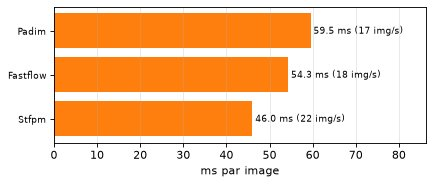

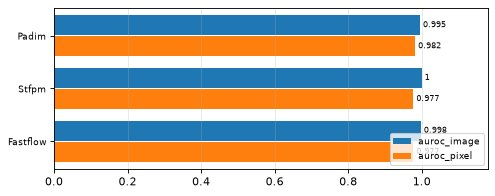

In [6]:
reference = pd.DataFrame(  # resultats de reference (recette et notebook 14)
    [  # une ligne par methode
        {"methode": "Padim (recette)", "auroc_image": 0.995, "auroc_pixel": 0.982},  # PaDiM selon la recette
        {"methode": "Stfpm (recette, 15 epoques)", "auroc_image": 1.000, "auroc_pixel": 0.977},  # STFPM selon la recette
        {"methode": "Fastflow (recette, 15 epoques)", "auroc_image": 1.000, "auroc_pixel": 0.972},  # FastFlow selon la recette
        {"methode": "PatchCore toolbox (notebook 14)", "auroc_image": 1.000, "auroc_pixel": 0.982},  # PatchCore ecrit a la main
    ]
).set_index("methode")  # indexe par nom de methode
display(reference)  # affiche les references
viz.compare_runs(table, ["auroc_image", "auroc_pixel"])  # barres comparant les AUROC des methodes
viz.latency_bars(table["ms_par_image"].to_dict())  # barres de vitesse (ms par image)

### Les memes images, les cartes de chaque methode

Chaque methode a sa propre echelle (distance de Mahalanobis, ecart etudiant / professeur,
vraisemblance) : les couleurs vont de la mediane des pixels normaux de validation (froid) a deux
fois l'ecart entre cette mediane et le seuil pixel (chaud). Contour vert : verite terrain.

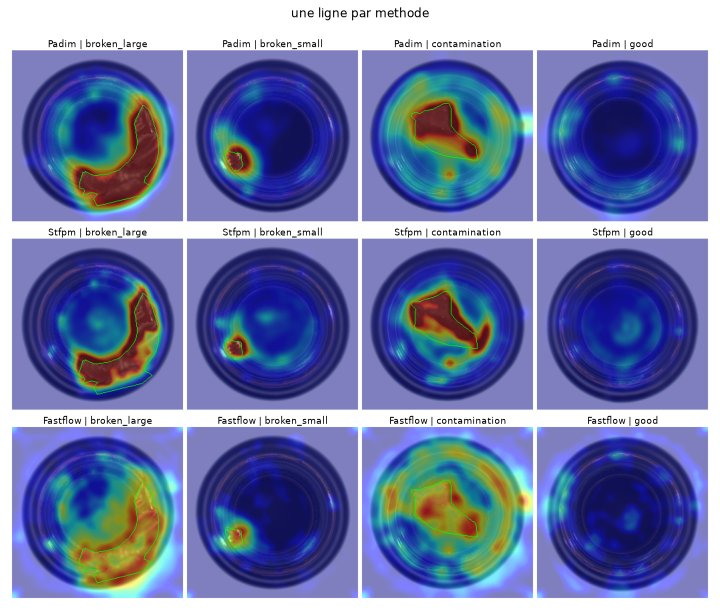

In [7]:
def with_contour(rgb: np.ndarray, mask: np.ndarray) -> np.ndarray:  # dessine en vert le contour du masque de verite sur l'image
    out = np.ascontiguousarray(rgb.copy())  # copie rangee d'un bloc en memoire (exige par les dessins OpenCV)
    # contours exterieurs des zones de defaut, simplifies (seulement les points utiles)
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, (0, 255, 0), 1)  # trace tous les contours (-1) en vert, epaisseur 1 pixel
    return out  # image annotee


# une image par type de defaut + une normale
picks = list(frames["test"][test_labels == 1].groupby("defect_type").head(1).index) + list(frames["test"][test_labels == 0].index[:1])
tiles, titles = [], []  # vignettes a afficher et leurs titres
for name, run in runs.items():  # pour chaque methode reussie
    low, high = run["map_median"], run["thresholds"]["pixel"]  # bas de l'echelle (mediane des normales) et seuil pixel
    for i in picks:  # pour chaque image choisie
        # carte fondue sur l'image, couleurs de low (froid) a low + 2 x (seuil - low) (chaud)
        heat = viz.overlay_heatmap(images["test"][i], run["maps"][i], alpha=0.5, vmin=low, vmax=low + 2 * (high - low))
        tiles.append(with_contour(heat, test_masks[i]))  # ajoute le contour vert de la verite
        titles.append(f"{name} | {frames['test'].loc[i, 'defect_type']}")  # titre : methode et type de defaut
viz.grid(tiles, titles, ncols=len(picks), size=2.2, suptitle="une ligne par methode")  # une ligne par methode, une colonne par image

## Etape 12 - Sauvegarder et exporter : exporter la meilleure methode

Le meilleur AUROC pixel (puis image) est exporte : pre-traitement anomalib + reseau + carte +
score dans un seul ONNX. Certains modeles d'anomalib figent la taille du lot dans leur graphe
(PatchCore, DFM) : on essaie un lot dynamique, on le verifie avec un AUTRE lot, et sinon on
reexporte avec un lot fixe de 1 (et la carte du modele le dit : `dynamic_batch: false`).

In [8]:
best_name = table.sort_values(["auroc_pixel", "auroc_image"], ascending=False).index[0]  # meilleure : AUROC pixel puis image
best = runs[best_name]  # ses details
model = best["model"].eval().cpu()  # son modele complet, en mode evaluation, sur CPU
onnx_path = OUT / "model.onnx"  # fichier ONNX a ecrire


def export(batch: torch.Tensor, dynamic: bool) -> None:  # exporte `model` en ONNX ; dynamic = taille de lot libre
    """Ancien exporteur (le plus tolerant) ; s'il refuse le modele, exporteur dynamo (torch.export)."""
    names = {"input_names": ["input"], "output_names": ["anomaly_map", "score"], "opset_version": 18}  # reglages communs aux 2 essais
    with warnings.catch_warnings():  # dans ce bloc, les avertissements sont geres a part ...
        warnings.simplefilter("ignore")  # ... et masques
        try:  # premier essai : ancien exporteur (par tracage)
            axes = {"input": {0: "batch"}, "anomaly_map": {0: "batch"}, "score": {0: "batch"}} if dynamic else None  # axe 0 (lot) libre
            torch.onnx.export(model, (batch,), str(onnx_path), dynamic_axes=axes, dynamo=False, **names)  # export par tracage
        except Exception as error:  # noqa: BLE001 - si l'ancien exporteur refuse le modele
            print("ancien exporteur en echec :", str(error).splitlines()[0][:120], "-> exporteur dynamo")  # signale le changement
            shapes = {"x": {0: torch.export.Dim("batch", min=1, max=1024)}} if dynamic else None  # lot libre de 1 a 1024 pour l'entree x
            # nouvel exporteur (dynamo) ; external_data=False : poids dans le meme fichier .onnx
            torch.onnx.export(model, (batch,), str(onnx_path), dynamic_shapes=shapes, dynamo=True, external_data=False, **names)


export(x_val[:2], dynamic=True)  # premier export : lot de 2, taille de lot libre
dynamic_batch = True  # on suppose que le lot libre fonctionne
try:  # verification avec un AUTRE lot (3 images)
    # si la taille du lot est figee dans le graphe, cet appel echoue
    ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"]).run(None, {"input": x_val[:3].numpy()})
except Exception:  # noqa: BLE001 - lot fige dans le graphe
    export(x_val[:1], dynamic=False)  # reexport avec un lot fixe de 1
    dynamic_batch = False  # la carte du modele le dira
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le fichier ONNX final (CPU)
check = x_val[:3]  # 3 images de controle
with torch.no_grad():  # sans gradient : simple prediction
    expected = [t.numpy() for t in model(check)]  # reponses PyTorch (carte, score)
step = 3 if dynamic_batch else 1  # images par appel ONNX : 3 si le lot est libre, sinon 1 a la fois
chunks = [session.run(None, {"input": check[i : i + step].numpy()}) for i in range(0, len(check), step)]  # reponses ONNX, appel par appel
got = [np.concatenate([c[k] for c in chunks]) for k in range(2)]  # recolle les cartes (k = 0) et les scores (k = 1)
report = {}  # ecart maximal pour chaque sortie
for name, t, o in zip(("anomaly_map", "score"), expected, got):  # pour chaque sortie : nom, reponse PyTorch, reponse ONNX
    diff, scale = float(np.abs(t - o).max()), float(np.abs(t).max())  # plus grand ecart, et ordre de grandeur des valeurs
    report[name] = diff  # note l'ecart
    # les deux reponses doivent concorder, avec une tolerance relative a l'echelle ; sinon arret
    assert diff <= 1e-4 + 1e-3 * scale, f"{name} : ecart ONNX / PyTorch {diff:.2e} pour une echelle {scale:.2e}"


def latency_ms(fn, repeat: int = 10) -> float:  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels de chauffe non chronometres ...
        fn()  # ... (le premier appel est toujours plus lent : allocations, caches)
    start = time.perf_counter()  # chrono precis
    for _ in range(repeat):  # `repeat` appels chronometres
        fn()  # un appel du modele
    return round(1000 * (time.perf_counter() - start) / repeat, 2)  # duree moyenne en ms, arrondie a 2 decimales


one = x_val[:1]  # une seule image (lot de 1) : la latence vue par la production
with torch.no_grad():  # sans gradient
    latency = {  # latence des deux moteurs
        "torch_cpu_ms": latency_ms(lambda: model(one)),  # PyTorch sur CPU (lambda : petite fonction sans nom)
        "onnxruntime_cpu_ms": latency_ms(lambda: session.run(None, {"input": one.numpy()})),  # onnxruntime sur CPU
    }
print(f"{best_name} exporte | lot dynamique {dynamic_batch} | ecarts {report} | latence {latency}")  # bilan de l'export

channels = int(x_val.shape[1])  # nombre de canaux des images (3 en couleur)
card = {  # carte du modele : tout ce que la production doit savoir pour l'utiliser
    "task": "anomaly",  # type de tache : detection d'anomalies
    "model_name": best_name,  # nom de la methode exportee
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),  # date et heure de creation (UTC)
    "framework": {"torch": torch.__version__, "onnxruntime": ort.__version__, "anomalib": anomalib.__version__},  # versions
    "input": {  # description de l'entree attendue
        "name": "input",  # nom de l'entree dans le graphe ONNX
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": IMAGE_SIZE,  # hauteur en pixels
        "width": IMAGE_SIZE,  # largeur en pixels
        "channels": channels,  # nombre de canaux
        "color": "RGB" if channels == 3 else "GRAY",  # couleur ou gris
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle [0, 1] a faire avant l'envoi
        "mean": [],  # vide : la normalisation est deja dans le modele (pre-traitement anomalib)
        "std": [],  # vide aussi, meme raison
        "resize": "stretch",  # redimensionnement en etirant (proportions non conservees)
        "letterbox_pad_value": None,  # pas de letterbox (bandes ajoutees pour garder les proportions)
        "dynamic_batch": dynamic_batch,  # taille de lot libre ou fixee a 1, selon la verification
        "read_color": COLOR,  # mode de lecture de l'image
    },
    "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # pretraitement : resize, interpolation automatique
    "outputs": [  # description des deux sorties
        {  # sortie 1 : la carte
            "name": "anomaly_map",  # son nom
            "shape": ["batch", 1, IMAGE_SIZE, IMAGE_SIZE],  # sa forme : lot, 1 canal, hauteur, largeur
            "description": "carte d'anomalie lissee (plus haut = plus anormal)",  # ce qu'elle contient
        },
        {"name": "score", "shape": ["batch"], "description": "score image ; anomalie si score > thresholds.image"},  # sortie 2 : le score
    ],
    "class_names": [],  # pas de classes : seulement normal ou anomalie
    "thresholds": best["thresholds"],  # seuils image et pixel calibres sur la validation
    # regle de decision et origine du seuil
    "postprocess": {"decision": "score > thresholds.image", "calibration": f"quantile {IMAGE_QUANTILE} des normales de validation"},
    "metrics": {  # metriques principales du test, arrondies a 4 decimales
        k: round(v, 4)  # cle -> valeur arrondie a 4 decimales ...
        for k, v in best["metrics"].items()  # ... pour chaque metrique de la meilleure methode ...
        if k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "f1")  # ... si elle fait partie de ces 5
    },
    "latency_ms": latency,  # latences mesurees
    "files": {"onnx": "model.onnx"},  # fichier du modele, a cote de la carte
    # note libre : methode, backbone, ecarts de la verification
    "notes": f"anomalib {best_name} (backbone {BACKBONE}), notebook 15 ; normalisation incluse ; ecarts ONNX / PyTorch {report}",
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible
print("ecrit :", sorted(p.name for p in OUT.iterdir()))  # liste les fichiers du dossier de sortie

Padim exporte | lot dynamique True | ecarts {'anomaly_map': 3.254413604736328e-05, 'score': 3.814697265625e-06} | latence {'torch_cpu_ms': 61.21, 'onnxruntime_cpu_ms': 37.16}
ecrit : ['anomalib_data', 'lightning', 'model.onnx', 'model_card.json', 'split.csv']


## Resultats

In [9]:
display(table[["auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "construction_s", "ms_par_image"]])  # tableau final
print("exporte :", best_name, "->", onnx_path)  # methode exportee et chemin du fichier

,auroc_image,auroc_pixel,recall,false_alarm_rate,construction_s,ms_par_image
methode,,,,,,
Padim,0.9952,0.9820,0.9841,0.05,12,59.5
Stfpm,1.0000,0.9772,1.0000,0.05,227,46.0
Fastflow,0.9976,0.9770,1.0000,0.05,90,54.3


exporte : Padim -> outputs/notebooks/15_anomalies_anomalib/model.onnx


## Adapter a tes donnees

- Changer `DATA_DIR` (rangement MVTec) ou ecrire un catalogue path / label / defect_type /
  mask_path / split comme dans les notebooks 13 et 14.
- Ajouter une methode : une ligne dans `METHODS` avec le NOM DE CLASSE anomalib (Cflow, Csflow,
  Dfkde, Dfm, Dsr, Ganomaly, Uflow, Supersimplenet, Vlmad...) et ses arguments ; le reste du
  protocole ne change pas.
- Pieces non alignees : eviter PaDiM (une gaussienne PAR POSITION) ; preferer PatchCore.
- Textures (acier, tuiles) : PatchCore et PaDiM tiennent, les methodes entrainees demandent
  beaucoup plus d'epoques (GPU) ; voir le banc de la recette (`recipes/anomaly/README.md`).

## Passer en production

```yaml
# recipes/anomaly/configs/anomalib_padim_bottle.yaml (une configuration par methode)
data: {root: data/raw/mvtec_bottle, layout: mvtec}
normal_labels: [good]
split: {file: outputs/anomaly/bottle_split.csv, val_fraction: 0.15}
preprocess: [{name: resize, size: 256}]
scoring: {gaussian_sigma: 4.0, image_score: max, image_quantile: 0.99}
method: anomalib
anomalib: {model: Padim, params: {backbone: resnet18, layers: [layer1, layer2, layer3]}}
```

```
python recipes/anomaly/scripts/run.py --config recipes/anomaly/configs/anomalib_padim_bottle.yaml
python recipes/anomaly/scripts/benchmark.py --outputs outputs/anomaly --markdown benchmark.md
python -m vtb.serve --model outputs/notebooks/15_anomalies_anomalib
```

Controle : le predicteur de production relit le dossier exporte par ce notebook et doit rendre
les memes scores ; le decoupage doit etre celui de la recette.

In [10]:
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - production seulement dans cette section (predicteur sans PyTorch)

predictor = OnnxPredictor(OUT)  # charge le modele ONNX et sa carte depuis le dossier exporte
picked = list(range(0, len(frames["test"]), max(1, len(frames["test"]) // 6)))[:6]  # 6 images du test reparties regulierement
# ecart de score entre le predicteur de production (depuis le fichier image brut) et le notebook, image par image
gaps = [abs(predictor(read_image(frames["test"].loc[i, "path"], predictor.color))["score"] - float(best["scores"][i])) for i in picked]
scale = float(np.abs(best["scores"]).max())  # ordre de grandeur des scores (chaque methode a sa propre echelle)
print(f"predicteur de production ({best_name}) : ecart max des scores {max(gaps):.2e} pour une echelle {scale:.2e}")  # bilan
assert max(gaps) <= 1e-3 * max(scale, 1e-6)  # tolerance : 0,1 % de l'echelle (1e-6 evite une tolerance nulle)

recipe_split = Path("outputs/anomaly/bottle_split.csv")  # decoupage ecrit par la recette
if recipe_split.exists():  # si la recette a deja ete lancee
    theirs = pd.read_csv(recipe_split, keep_default_na=False).set_index("path")["split"]  # partie de chaque image selon la recette
    ours = split.set_index("path")["split"]  # partie de chaque image selon ce notebook
    # identique si chaque image est dans la meme partie (reindex aligne les deux tableaux par chemin)
    print("decoupage identique a la recette :", bool((theirs.reindex(ours.index) == ours).all()))
for leftover in ("anomalib_data", "lightning"):  # copie pretraitee des normales, dossiers de Lightning : plus utiles
    shutil.rmtree(OUT / leftover, ignore_errors=True)  # supprime le dossier (pas d'erreur s'il n'existe pas)

predicteur de production (Padim) : ecart max des scores 5.72e-06 pour une echelle 5.15e+01
decoupage identique a la recette : True


## Pour aller plus loin

- `QUICK = False` sur GPU : PatchCore d'anomalib, Reverse Distillation, EfficientAd, DRAEM ;
  backbone `wide_resnet50_2` pour se rapprocher des chiffres des articles.
- Magnetic Tile (texture) : changer le catalogue (voir notebook 13, variante sur une texture) ; la recette
  donne PaDiM 0,928 et STFPM 0,663 (10 epoques CPU) en AUROC image, PatchCore 0,965.